# Project

## Introduction to the Project
The S&P 500 (Standard & Poor's 500) is a stock market index that tracks the performance of 500 of the largest publicly traded companies in the United States. It is widely regarded as one of the best representations of the U.S. stock market and economy. Over the long term, the S&P 500 has shown consistent growth, making it a key focus for long-term investors. However, it can also experience significant volatility in the short term.

In this project, we will make our first attempt to build a momentum-based strategy to trade the S&P 500 index. At the end of the project, you will have built a program that you can later expand and customise to suit your needs. We will use the python packages numpy, scipy and sqlite3, among others, in this project.

Tips: Review the code snippets that we went through during the course. Reorganize them and you are half-way done! Try experimenting with different configurations of the confidence interval, the lookback window and the forecast horizon. Be brave and experiment with different ways of deciding the position size. You may be surprised by your talent!

Re-organize your code from the exercises into a Python program that 
1. read prices from a database
2. calibrate a GBM model on each day when new prices are received.
3. forecast the price in e.g. 10 days and
   1. calculate the confidence interval of the forecast
   2. calculate the expected shortfall from the price forecast
4. code your trading signals using the price forecast and the expected shortfall.
5. store your postions into the *positions* table after each trade.
6. produce a 1-year backtest record from 2020-06-01 to 2021-05-31.

**Hint**

1. Collect all the code related to the GBM model into a class

In [1]:
import csv
import sqlite3
from contextlib import closing
from datetime import datetime

import numpy as np
from scipy.stats import norm

conn = sqlite3.connect("SP500.db")
cs = conn.cursor()


In [2]:
class GBM:
    """Geometric Brownian motion: dS = mu S dt + sigma S dW."""
    def __init__(self, seed=42):
        self.mu, self.sigma = [np.nan] * 2
        self.rng = np.random.default_rng(seed)   # fixed seed so bootstrap results are reproducible

    def simulate(self, N, K, Dt, S0):
        """K simulated paths of N steps of length Dt, starting at S0 (row 0 is S0)."""
        traj = np.full((N+1, K), np.nan)
        drift = (self.mu - self.sigma**2 / 2) * np.linspace(1, N, N) * Dt
        for i in range(K):
            W = np.sqrt(Dt) * np.cumsum(norm.rvs(size=N, random_state=self.rng))
            traj[1:, i] = S0 * np.exp(drift + self.sigma * W)
            traj[0, i] = S0
        return traj

    def calibrate(self, trajectory, Dt):
        """Estimate mu and sigma from a price path.
        1) log-transform the prices and take the increments (log returns),
        2) estimate the first two moments E[X] and E[X^2] by averaging over bootstrap samples,
        3) sigma = sqrt(Var[X] / Dt), mu = E[X] / Dt + sigma^2 / 2 (Ito correction)."""
        increments = np.diff(np.log(np.asarray(trajectory, dtype=float)))
        moments = [0, 0]
        n_iter = 10
        for _ in range(n_iter):
            X = self.rng.choice(increments, size=len(increments) // 2)
            moments[0] += np.mean(X) / n_iter
            moments[1] += np.mean(X**2) / n_iter
        std = np.sqrt(moments[1] - moments[0]**2)
        self.sigma = std / np.sqrt(Dt)
        self.mu = moments[0] / Dt + self.sigma**2 / 2

    def forecast(self, latest, T, confidence):
        """Expected price after time T and the central `confidence` interval of the price at T.
        ln(S_T / S_0) ~ Normal((mu - sigma^2/2) T, sigma^2 T)."""
        m = (self.mu - self.sigma**2 / 2) * T
        s = self.sigma * np.sqrt(T)
        Q = norm.ppf([(1 - confidence) / 2, (1 + confidence) / 2], loc=m, scale=s)
        return {'expected': latest * np.exp(self.mu * T), 'interval': latest * np.exp(Q)}

    def expected_shortfall(self, T, confidence, short=False):
        """Expected shortfall of the log-return loss over horizon T at level `confidence` (e.g. 0.95):
        long position:  ES = -m + s * pdf(ppf(confidence)) / (1 - confidence)
        short position: ES = +m + s * pdf(ppf(confidence)) / (1 - confidence)  (a short loses when the price rises)
        with m = (mu - sigma^2/2) T and s = sigma sqrt(T)."""
        m = (self.mu - self.sigma**2 / 2) * T
        s = self.sigma * np.sqrt(T)
        tail = s * norm.pdf(norm.ppf(confidence)) / (1 - confidence)
        return (m + tail) if short else (-m + tail)

In [3]:
# test your code here
model = GBM()
model.mu = 0.3
model.sigma = 0.2
simulated = model.simulate(500, 1, 1/250, 100)
simulated = simulated[:, 0]

model2 = GBM()
model2.calibrate(simulated, 1/250)

print(F"Calibrated: mu = {model2.mu}, sigma = {model2.sigma}")

# A single 2-year path estimates sigma well but mu only roughly (drift is hard to estimate from short samples).
# Averaging over many simulated paths shows the estimates land close to the true values:
paths = model.simulate(500, 200, 1/250, 100)
fits = []
for k in range(paths.shape[1]):
    m_k = GBM(seed=k)
    m_k.calibrate(paths[:, k], 1/250)
    fits.append((m_k.mu, m_k.sigma))
fits = np.array(fits)
print(F"Average over 200 paths: mu = {fits[:, 0].mean():.4f} (true 0.30), sigma = {fits[:, 1].mean():.4f} (true 0.20)")

Calibrated: mu = 0.34944420989369895, sigma = 0.19444548287505314
Average over 200 paths: mu = 0.2840 (true 0.30), sigma = 0.2003 (true 0.20)


2. Write a function that prepares the database for trading, i.e.
   1. load the historical prices into the *prices* table
   2. create the *positions* table
   3. initialize the *positions* table with the your initial cash reserve. The initial *time_of_trade* can be any date before the earliest possible trading date.

    Call this function *prepare*.

In [4]:
INITIAL_CASH = 1_000_000.0

def prepare():
    """Load SP500.csv into the prices table, create the positions table and seed it with the starting cash."""
    cs.execute("drop table if exists prices;")
    cs.execute("""
    create table prices (
        theday text primary key,
        price real
    );
    """)
    with closing(open('SP500.csv')) as datafile:
        reader = csv.DictReader(datafile, fieldnames=["date", "price"], delimiter='\t')
        rows = [(row['date'], float(row['price'])) for row in reader]
    cs.executemany("insert into prices values (?, ?);", rows)

    cs.execute("drop table if exists positions;")
    cs.execute("""
    create table positions (
        time_of_trade text,
        instrument text,
        quantity real,
        cash real,
        primary key (time_of_trade, instrument)
    );
    """)
    # initial position: no shares and the full cash reserve, dated before any possible trading day
    cs.execute("insert into positions values ('2019-12-31', 'SP500', 0, ?);", (INITIAL_CASH,))
    conn.commit()

In [5]:
# check whether you have loaded the prices correctly
prepare()
latest_prices = cs.execute("select * from prices order by theday desc limit 10")
for item in latest_prices:
    print(item)
print(cs.execute("select count(*), min(theday), max(theday) from prices").fetchone())
print(cs.execute("select * from positions").fetchall())

('2021-05-31', 4203.60009765625)
('2021-05-30', 4210.10009765625)
('2021-05-28', 4206.0)
('2021-05-27', 4217.10009765625)
('2021-05-26', 4196.0)
('2021-05-25', 4197.5)
('2021-05-24', 4204.7001953125)
('2021-05-23', 4153.2998046875)
('2021-05-21', 4161.39990234375)
('2021-05-20', 4165.5)
(750, '2019-01-02', '2021-05-31')
[('2019-12-31', 'SP500', 0.0, 1000000.0)]


3. Write a function that determines the trade size, i.e. how many units of the instrument you would like to own when the date is *which_day* and the price forecast of the instrument is *forecast* and the expected shortfall from the same forecast is *ES*.

In [6]:
RISK_BUDGET = 0.05   # target expected shortfall as a share of capital

def position_size(which_day, forecast, ES):
    """Units of SP500 to hold on which_day.
    Momentum rule: if today's price is below the forecast interval, the model expects the price to rise -> go long;
    if it is above the interval, the model expects a fall -> go short; otherwise stay flat.
    Size: exposure = capital * RISK_BUDGET / ES, so riskier forecasts (larger ES) mean smaller positions.
    ES is a dict with the expected shortfall of a long ('long') and of a short ('short') position."""
    cs.execute(F"""
    select quantity, cash from positions
    where instrument = 'SP500'
    and time_of_trade < '{which_day}'
    order by time_of_trade desc
    limit 1;
    """)
    qty, cash = cs.fetchall()[0]
    cs.execute(F"""
    select price from prices
    where theday <= '{which_day}'
    order by theday desc
    limit 1;
    """)
    price = cs.fetchall()[0][0]
    capital = cash + qty * price
    if price < forecast['interval'][0]:
        return round(capital * RISK_BUDGET / ES['long'] / price)
    elif price > forecast['interval'][1]:
        return -round(capital * RISK_BUDGET / ES['short'] / price)
    else:
        return 0

4. Write a function that, for a given date, calibrates a GBM model to the data prior to that date and that forecasts the price in 10 days. Call this function *analyse*.

In [7]:
LOOKBACK = 120      # trading days of history used to calibrate the model
HORIZON = 10        # forecast horizon in trading days
CONFIDENCE = 0.1    # width of the central forecast interval used for the signal
ES_LEVEL = 0.95     # expected shortfall confidence level
Dt = 1.0 / 252

def analyse(which_day):
    """Calibrate a GBM on the LOOKBACK prices strictly before which_day, forecast HORIZON days ahead,
    compute the expected shortfall and return the advised position (number of units)."""
    cs.execute(F"""
    select price from prices where theday < '{which_day}'
    order by theday desc limit {LOOKBACK};
    """)
    P = np.flipud(np.asarray(cs.fetchall())).flatten()
    model = GBM()
    model.calibrate(P, Dt)
    T = HORIZON * Dt
    forecast = model.forecast(P[-1], T, CONFIDENCE)
    ES = {'long': model.expected_shortfall(T, ES_LEVEL), 'short': model.expected_shortfall(T, ES_LEVEL, short=True)}
    return position_size(which_day, forecast, ES)

In [8]:
# Test the analyse function
test_dates = ['2021-05-09', '2021-05-14']
positions = [np.nan, np.nan]
for i in range(2):
    positions[i] = analyse(test_dates[i])
    print(F"{positions[i]} shares advised on {test_dates[i]}.")

251 shares advised on 2021-05-09.
0 shares advised on 2021-05-14.


5. The main loop of the program: Loop over the dates in the backtest period and use the *analyse* function to decide what to do on each day. Call this function *main*.

In [9]:
def main(begin_on):
    cs.execute(F"select theday from prices where theday >= '{begin_on}';")
    days = [d[0] for d in cs.fetchall()]
    asset = {
        'old': np.nan,
        'new': np.nan
    };
    cash = {
        'old': np.nan,
        'new': np.nan
    };
    cs.execute("delete from positions where time_of_trade > '2020-01-01';");
    for d in days:
        asset['new'] = analyse(d)
        cs.execute(F"""
        select quantity, cash from positions
        where time_of_trade < '{d}'
        order by time_of_trade desc
        limit 1;
        """);
        asset['old'], cash['old'] = cs.fetchall()[0];
        cs.execute(F"""
        select price from prices
        where theday <= '{d}'
        order by theday desc
        limit 1;
        """);
        latest = cs.fetchall()[0][0]
        trade_size = round(asset['new']) - round(asset['old']);
        if trade_size != 0:
            cash['new'] = cash['old'] - trade_size * latest;
            cs.execute(F"""
            insert into positions values
            ('{d}', 'SP500', {round(asset['new'])}, {cash['new']});
            """);
        conn.commit();



6. Connect to the database and create a *cursor* object associated with the connection. Share the connection and the cursor object across the program so that you don't have to connect to and disconnect from the database in every function of the program.

In [10]:
if __name__ == "__main__":
    with closing(sqlite3.connect("SP500.db")) as conn:
        with closing(conn.cursor()) as cs:
            prepare()
            main('2020-06-01')
    


In [11]:
# plot your track record
conn = sqlite3.connect("SP500.db")
cs = conn.cursor()

day1 = '2020-06-01'
day1_dt = datetime.strptime(day1, '%Y-%m-%d')

cs.execute(f"""
    select theday, quantity * price + cash as wealth
    from positions as PO
    join prices as PR
    on PO.time_of_trade = (
        select time_of_trade from positions
        where time_of_trade <= PR.theday
        order by time_of_trade desc limit 1
    )
    where theday >= '{day1}';
""")

records = cs.fetchall()

def calculate_T(record, day1_dt):
    theday, wealth = record
    theday_dt = datetime.strptime(theday, '%Y-%m-%d')
    T = (theday_dt - day1_dt).days
    return (T, wealth)

records = [calculate_T(record, day1_dt) for record in records]
W = np.asarray(records)

In [12]:
import matplotlib.pyplot as plt

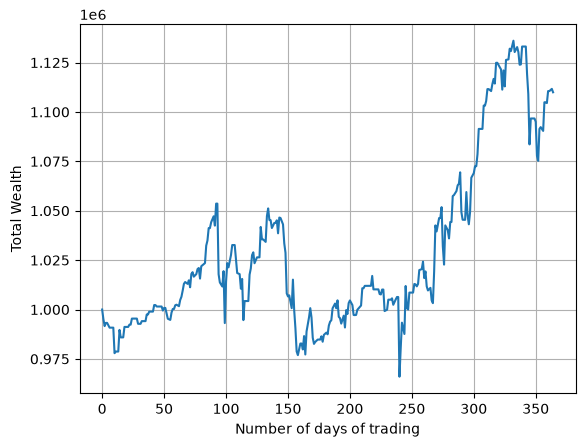

In [13]:
fig = plt.plot(W[:,0], W[:, 1])
plt.grid()
plt.xlabel("Number of days of trading")
plt.ylabel('Total Wealth');

## Performance of the backtest

The cells below measure the track record against simply buying the S&P 500 with the same starting cash on 2020-06-01 and holding it.

In [14]:
conn = sqlite3.connect("SP500.db")
cs = conn.cursor()
import pandas as pd

def backtest_record(begin_on='2020-06-01'):
    """Daily wealth series and trade log from the positions table."""
    rows = cs.execute(f"""
        select theday, quantity, cash, price, quantity * price + cash as wealth
        from positions as PO join prices as PR
        on PO.time_of_trade = (select time_of_trade from positions where time_of_trade <= PR.theday
                               order by time_of_trade desc limit 1)
        where theday >= '{begin_on}' order by theday;""").fetchall()
    df = pd.DataFrame(rows, columns=['day', 'quantity', 'cash', 'price', 'wealth']).set_index('day')
    trades = pd.DataFrame(cs.execute(f"select * from positions where time_of_trade >= '{begin_on}' order by time_of_trade").fetchall(),
                          columns=['time_of_trade', 'instrument', 'quantity', 'cash'])
    return df, trades

def summarize(df, trades, initial=INITIAL_CASH):
    wealth = df['wealth']
    bh = initial / df['price'].iloc[0] * df['price']
    dd = wealth / wealth.cummax() - 1
    bh_dd = bh / bh.cummax() - 1
    return pd.Series({
        'Strategy final wealth': wealth.iloc[-1], 'Strategy return': wealth.iloc[-1] / initial - 1,
        'Strategy max drawdown': dd.min(), 'Number of trades': len(trades),
        'Days long': int((df['quantity'] > 0).sum()), 'Days short': int((df['quantity'] < 0).sum()),
        'Days flat': int((df['quantity'] == 0).sum()),
        'Average gross exposure / wealth': (df['quantity'].abs() * df['price'] / wealth).mean(),
        'Max gross exposure / wealth': (df['quantity'].abs() * df['price'] / wealth).max(),
        'Days long with exposure above wealth': int(((df['quantity'] * df['price']) > wealth).sum()),
        'Buy and hold final wealth': bh.iloc[-1], 'Buy and hold return': bh.iloc[-1] / initial - 1,
        'Buy and hold max drawdown': bh_dd.min()})

record, trades = backtest_record()
display(summarize(record, trades).to_frame('Value'))
display(trades.head(10))

,Value
Strategy final wealth,1.109960e+06
Strategy return,1.099605e-01
Strategy max drawdown,-8.314378e-02
Number of trades,2.850000e+02
Days long,2.110000e+02
Days short,3.600000e+01
Days flat,6.400000e+01
Average gross exposure / wealth,6.666677e-01
Max gross exposure / wealth,1.464043e+00
Days long with exposure above wealth,7.800000e+01


,time_of_trade,instrument,quantity,cash
0,2020-06-01,SP500,-102.0,1.310202e+06
1,2020-06-02,SP500,-97.0,1.294757e+06
2,2020-06-03,SP500,-112.0,1.341635e+06
3,2020-06-04,SP500,0.0,9.932365e+05
4,2020-06-05,SP500,-108.0,1.337562e+06
5,2020-06-07,SP500,0.0,9.908281e+05
6,2020-06-10,SP500,94.0,6.931865e+05
7,2020-06-11,SP500,108.0,6.507819e+05
8,2020-06-12,SP500,0.0,9.787347e+05
9,2020-06-14,SP500,108.0,6.550587e+05


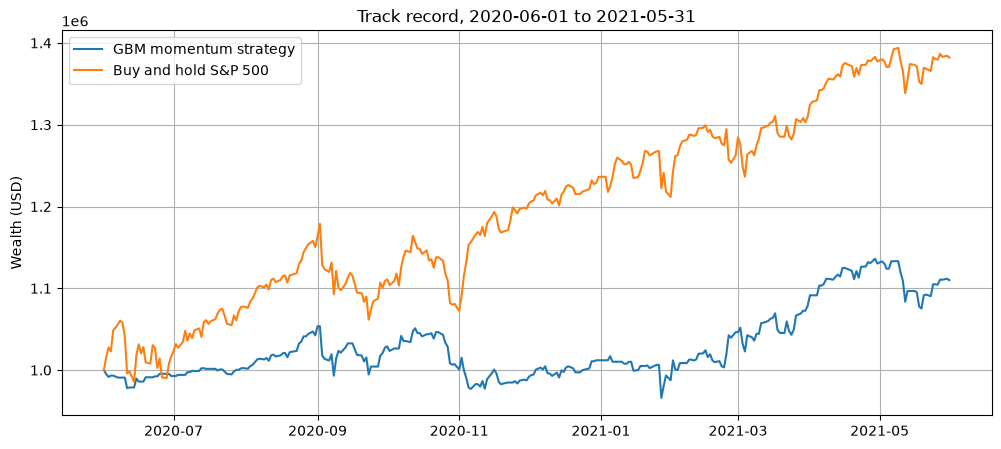

In [15]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(pd.to_datetime(record.index), record['wealth'], label='GBM momentum strategy')
ax.plot(pd.to_datetime(record.index), INITIAL_CASH / record['price'].iloc[0] * record['price'], label='Buy and hold S&P 500')
ax.set_title('Track record, 2020-06-01 to 2021-05-31')
ax.set_ylabel('Wealth (USD)')
ax.grid(True)
ax.legend()
plt.show()

## Experimenting with the configuration

As suggested in the tips, the backtest is re-run for other lookback windows, interval widths and horizons. The default configuration (lookback 120, confidence 0.1, horizon 10) is restored at the end so the database holds the main backtest.

In [16]:
results = []
default = (LOOKBACK, CONFIDENCE, HORIZON)
for LOOKBACK, CONFIDENCE, HORIZON in [(60, 0.1, 10), (120, 0.1, 10), (250, 0.1, 10), (120, 0.5, 10), (120, 0.1, 5), (120, 0.1, 20)]:
    main('2020-06-01')
    df, tr = backtest_record()
    s = summarize(df, tr)
    results.append({'lookback': LOOKBACK, 'confidence': CONFIDENCE, 'horizon': HORIZON,
                    'return': s['Strategy return'], 'max drawdown': s['Strategy max drawdown'],
                    'trades': s['Number of trades'], 'days long': s['Days long'], 'days short': s['Days short']})
LOOKBACK, CONFIDENCE, HORIZON = default
main('2020-06-01')   # restore the main backtest in the database
display(pd.DataFrame(results).round(4))

,lookback,confidence,horizon,return,max drawdown,trades,days long,days short
0,60,0.1,10,-0.0871,-0.2373,297.0,219.0,31.0
1,120,0.1,10,0.1100,-0.0831,285.0,211.0,36.0
2,250,0.1,10,0.0850,-0.0687,266.0,164.0,49.0
3,120,0.5,10,0.0850,-0.0318,65.0,34.0,0.0
4,120,0.1,5,0.0839,-0.1605,295.0,171.0,67.0
5,120,0.1,20,0.1682,-0.0524,292.0,241.0,21.0


## Interpretation

**Main backtest (2020-06-01 to 2021-05-31; lookback 120, horizon 10, interval width 0.1, ES at 95%):**

* The strategy grew $1,000,000 to $1,109,960, an **11.0% return**, with a worst peak-to-trough drawdown of 8.3%.
* Buying and holding the S&P 500 over the same period returned **38.2%**, with a 9.9% drawdown. The strategy took a slightly smaller drawdown but gave up most of the gain.
* Over the 311 price days it was long on 211, short on 36 and flat on 64, and it changed its position 285 times.

**Why it lagged:** this period was a strong, steady recovery rally. The signal only goes long when the latest price falls below the narrow forecast interval, and it often flips to flat or short after a strong up-day. Missing part of a rally is costly.

The expected-shortfall sizing (5% of capital divided by ES) changes the exposure from day to day. On average, the position's gross market value was only 67% of account wealth, against 100% for buy and hold. Calm periods have a low ES, so sizing can go above the account value: up to 146% of wealth, and above 100% on 78 of the long days. Even so, the strategy was flat or short for 100 days and averaged well under full exposure. That cost it most of the rally.

**Configuration experiments:**

* **Lookback matters a lot.** 60 days lost 8.7% with a 23.7% drawdown. 120 days made 11.0%, and 250 days made 8.5%. A short window makes the drift estimate noisy, so the signal flips often.
* **A longer horizon helped.** A 20-day horizon returned 16.8% with only a 5.2% drawdown, while a 5-day horizon returned 8.4% with a 16.1% drawdown.
* **A wider interval (0.5) trades much less.** It made 65 position changes, was never short and spent most days flat. It returned 8.5% with the smallest drawdown (3.2%).
* **No configuration beat buy and hold** in this one-year bull market. The best one (20-day horizon) is still about 21 percentage points behind.

**Decision and next steps:**

* I would not trade this configuration with real money. Results swing from -8.7% to +16.8% depending on parameters chosen after the fact. That is a sign of overfitting risk, not a robust edge, and all of it comes from a single year.
* No transaction costs or financing costs (for positions above 100% of wealth, or for shorts) are included, and the main version trades almost daily. Real costs would reduce the 11.0% further.
* Improvements to test: (1) choose parameters on an earlier period and test them on a later one (walk-forward), not on the same year; (2) add a cost model, a minimum holding period and a leverage cap; (3) let the long signal persist while the trend holds instead of resetting daily; (4) test across bull, bear and sideways markets, for example including 2022; (5) the data includes 52 Sunday futures sessions in the period, so the time step of 1/252 slightly overstates elapsed time. A calendar-aware Dt would be more precise.